# Covid 19 Data Analysis and Model Modelling 

In [29]:
# Initial Imports

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Importing the Data

In [30]:
world = pd.read_csv("./data/worldometer_data.csv")
world

,Country/Region,Continent,Population,TotalCases,NewCases,TotalDeaths,NewDeaths,TotalRecovered,NewRecovered,ActiveCases,"Serious,Critical",Tot Cases/1M pop,Deaths/1M pop,TotalTests,Tests/1M pop,WHO Region
0,USA,North America,3.311981e+08,5032179,NaN,162804.0,NaN,2576668.0,NaN,2292707.0,18296.0,15194.0,492.0,63139605.0,190640.0,Americas
1,Brazil,South America,2.127107e+08,2917562,NaN,98644.0,NaN,2047660.0,NaN,771258.0,8318.0,13716.0,464.0,13206188.0,62085.0,Americas
2,India,Asia,1.381345e+09,2025409,NaN,41638.0,NaN,1377384.0,NaN,606387.0,8944.0,1466.0,30.0,22149351.0,16035.0,South-EastAsia
3,Russia,Europe,1.459409e+08,871894,NaN,14606.0,NaN,676357.0,NaN,180931.0,2300.0,5974.0,100.0,29716907.0,203623.0,Europe
4,South Africa,Africa,5.938157e+07,538184,NaN,9604.0,NaN,387316.0,NaN,141264.0,539.0,9063.0,162.0,3149807.0,53044.0,Africa
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
204,Montserrat,North America,4.992000e+03,13,NaN,1.0,NaN,10.0,NaN,2.0,NaN,2604.0,200.0,61.0,12220.0,NaN
205,Caribbean Netherlands,North America,2.624700e+04,13,NaN,NaN,NaN,7.0,NaN,6.0,NaN,495.0,NaN,424.0,16154.0,NaN
206,Falkland Islands,South America,3.489000e+03,13,NaN,NaN,NaN,13.0,NaN,0.0,NaN,3726.0,NaN,1816.0,520493.0,NaN
207,Vatican City,Europe,8.010000e+02,12,NaN,NaN,NaN,12.0,NaN,0.0,NaN,14981.0,NaN,NaN,NaN,Europe


# Preparing the Dataset.

### Adding the Total Cases/Death and New Cases/Death columns into one.

In [31]:
world["TotalCases"] = world["TotalCases"] + world["NewCases"].fillna(0)

world

,Country/Region,Continent,Population,TotalCases,NewCases,TotalDeaths,NewDeaths,TotalRecovered,NewRecovered,ActiveCases,"Serious,Critical",Tot Cases/1M pop,Deaths/1M pop,TotalTests,Tests/1M pop,WHO Region
0,USA,North America,3.311981e+08,5032179.0,NaN,162804.0,NaN,2576668.0,NaN,2292707.0,18296.0,15194.0,492.0,63139605.0,190640.0,Americas
1,Brazil,South America,2.127107e+08,2917562.0,NaN,98644.0,NaN,2047660.0,NaN,771258.0,8318.0,13716.0,464.0,13206188.0,62085.0,Americas
2,India,Asia,1.381345e+09,2025409.0,NaN,41638.0,NaN,1377384.0,NaN,606387.0,8944.0,1466.0,30.0,22149351.0,16035.0,South-EastAsia
3,Russia,Europe,1.459409e+08,871894.0,NaN,14606.0,NaN,676357.0,NaN,180931.0,2300.0,5974.0,100.0,29716907.0,203623.0,Europe
4,South Africa,Africa,5.938157e+07,538184.0,NaN,9604.0,NaN,387316.0,NaN,141264.0,539.0,9063.0,162.0,3149807.0,53044.0,Africa
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
204,Montserrat,North America,4.992000e+03,13.0,NaN,1.0,NaN,10.0,NaN,2.0,NaN,2604.0,200.0,61.0,12220.0,NaN
205,Caribbean Netherlands,North America,2.624700e+04,13.0,NaN,NaN,NaN,7.0,NaN,6.0,NaN,495.0,NaN,424.0,16154.0,NaN
206,Falkland Islands,South America,3.489000e+03,13.0,NaN,NaN,NaN,13.0,NaN,0.0,NaN,3726.0,NaN,1816.0,520493.0,NaN
207,Vatican City,Europe,8.010000e+02,12.0,NaN,NaN,NaN,12.0,NaN,0.0,NaN,14981.0,NaN,NaN,NaN,Europe


In [32]:
world["TotalDeaths"] = world["TotalDeaths"] + world["NewDeaths"].fillna(0)

world

,Country/Region,Continent,Population,TotalCases,NewCases,TotalDeaths,NewDeaths,TotalRecovered,NewRecovered,ActiveCases,"Serious,Critical",Tot Cases/1M pop,Deaths/1M pop,TotalTests,Tests/1M pop,WHO Region
0,USA,North America,3.311981e+08,5032179.0,NaN,162804.0,NaN,2576668.0,NaN,2292707.0,18296.0,15194.0,492.0,63139605.0,190640.0,Americas
1,Brazil,South America,2.127107e+08,2917562.0,NaN,98644.0,NaN,2047660.0,NaN,771258.0,8318.0,13716.0,464.0,13206188.0,62085.0,Americas
2,India,Asia,1.381345e+09,2025409.0,NaN,41638.0,NaN,1377384.0,NaN,606387.0,8944.0,1466.0,30.0,22149351.0,16035.0,South-EastAsia
3,Russia,Europe,1.459409e+08,871894.0,NaN,14606.0,NaN,676357.0,NaN,180931.0,2300.0,5974.0,100.0,29716907.0,203623.0,Europe
4,South Africa,Africa,5.938157e+07,538184.0,NaN,9604.0,NaN,387316.0,NaN,141264.0,539.0,9063.0,162.0,3149807.0,53044.0,Africa
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
204,Montserrat,North America,4.992000e+03,13.0,NaN,1.0,NaN,10.0,NaN,2.0,NaN,2604.0,200.0,61.0,12220.0,NaN
205,Caribbean Netherlands,North America,2.624700e+04,13.0,NaN,NaN,NaN,7.0,NaN,6.0,NaN,495.0,NaN,424.0,16154.0,NaN
206,Falkland Islands,South America,3.489000e+03,13.0,NaN,NaN,NaN,13.0,NaN,0.0,NaN,3726.0,NaN,1816.0,520493.0,NaN
207,Vatican City,Europe,8.010000e+02,12.0,NaN,NaN,NaN,12.0,NaN,0.0,NaN,14981.0,NaN,NaN,NaN,Europe


In [33]:
# Cheking if some data is empty in these added columns
print(world["TotalCases"].isna().sum())
print(world["TotalDeaths"].isna().sum())

0
21


In [34]:
# Print only those columns which are empty.
world[world["TotalDeaths"].isna()]

,Country/Region,Continent,Population,TotalCases,NewCases,TotalDeaths,NewDeaths,TotalRecovered,NewRecovered,ActiveCases,"Serious,Critical",Tot Cases/1M pop,Deaths/1M pop,TotalTests,Tests/1M pop,WHO Region
168,Mongolia,Asia,3283344.0,293.0,NaN,NaN,NaN,260.0,NaN,33.0,1.0,89.0,NaN,38334.0,11675.0,WesternPacific
169,Eritrea,Africa,3551175.0,282.0,NaN,NaN,NaN,225.0,NaN,57.0,NaN,79.0,NaN,NaN,NaN,Africa
172,Faeroe Islands,Europe,48882.0,266.0,NaN,NaN,NaN,192.0,NaN,74.0,1.0,5442.0,NaN,43045.0,880590.0,NaN
174,Cambodia,Asia,16741375.0,243.0,NaN,NaN,NaN,210.0,NaN,33.0,1.0,15.0,NaN,67807.0,4050.0,WesternPacific
177,Gibraltar,Europe,33690.0,190.0,NaN,NaN,NaN,184.0,NaN,6.0,NaN,5640.0,NaN,23063.0,684565.0,NaN
184,Seychelles,Africa,98408.0,126.0,NaN,NaN,NaN,124.0,NaN,2.0,NaN,1280.0,NaN,NaN,NaN,Africa
186,Bhutan,Asia,772443.0,105.0,NaN,NaN,NaN,93.0,NaN,12.0,NaN,136.0,NaN,54589.0,70671.0,South-EastAsia
190,French Polynesia,Australia/Oceania,281072.0,64.0,NaN,NaN,NaN,62.0,NaN,2.0,NaN,228.0,NaN,5849.0,20810.0,NaN
191,St. Vincent Grenadines,North America,110976.0,56.0,NaN,NaN,NaN,46.0,NaN,10.0,NaN,505.0,NaN,2447.0,22050.0,NaN
193,Macao,Asia,650193.0,46.0,NaN,NaN,NaN,46.0,NaN,0.0,NaN,71.0,NaN,4071.0,6261.0,NaN


### Dropping the New Cases and New Deaths Columns.

In [35]:
# Dropping the columns which are empty
world.drop("NewCases", axis=1, inplace = True)

world.drop("NewDeaths", axis=1, inplace = True)

world

,Country/Region,Continent,Population,TotalCases,TotalDeaths,TotalRecovered,NewRecovered,ActiveCases,"Serious,Critical",Tot Cases/1M pop,Deaths/1M pop,TotalTests,Tests/1M pop,WHO Region
0,USA,North America,3.311981e+08,5032179.0,162804.0,2576668.0,NaN,2292707.0,18296.0,15194.0,492.0,63139605.0,190640.0,Americas
1,Brazil,South America,2.127107e+08,2917562.0,98644.0,2047660.0,NaN,771258.0,8318.0,13716.0,464.0,13206188.0,62085.0,Americas
2,India,Asia,1.381345e+09,2025409.0,41638.0,1377384.0,NaN,606387.0,8944.0,1466.0,30.0,22149351.0,16035.0,South-EastAsia
3,Russia,Europe,1.459409e+08,871894.0,14606.0,676357.0,NaN,180931.0,2300.0,5974.0,100.0,29716907.0,203623.0,Europe
4,South Africa,Africa,5.938157e+07,538184.0,9604.0,387316.0,NaN,141264.0,539.0,9063.0,162.0,3149807.0,53044.0,Africa
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
204,Montserrat,North America,4.992000e+03,13.0,1.0,10.0,NaN,2.0,NaN,2604.0,200.0,61.0,12220.0,NaN
205,Caribbean Netherlands,North America,2.624700e+04,13.0,NaN,7.0,NaN,6.0,NaN,495.0,NaN,424.0,16154.0,NaN
206,Falkland Islands,South America,3.489000e+03,13.0,NaN,13.0,NaN,0.0,NaN,3726.0,NaN,1816.0,520493.0,NaN
207,Vatican City,Europe,8.010000e+02,12.0,NaN,12.0,NaN,0.0,NaN,14981.0,NaN,NaN,NaN,Europe


# EDA (Exploratory Data Analysis)

### Now we will make Different Charts Related to Different factors on which Corona i.e Covid-19 had affects on different parts of the world.

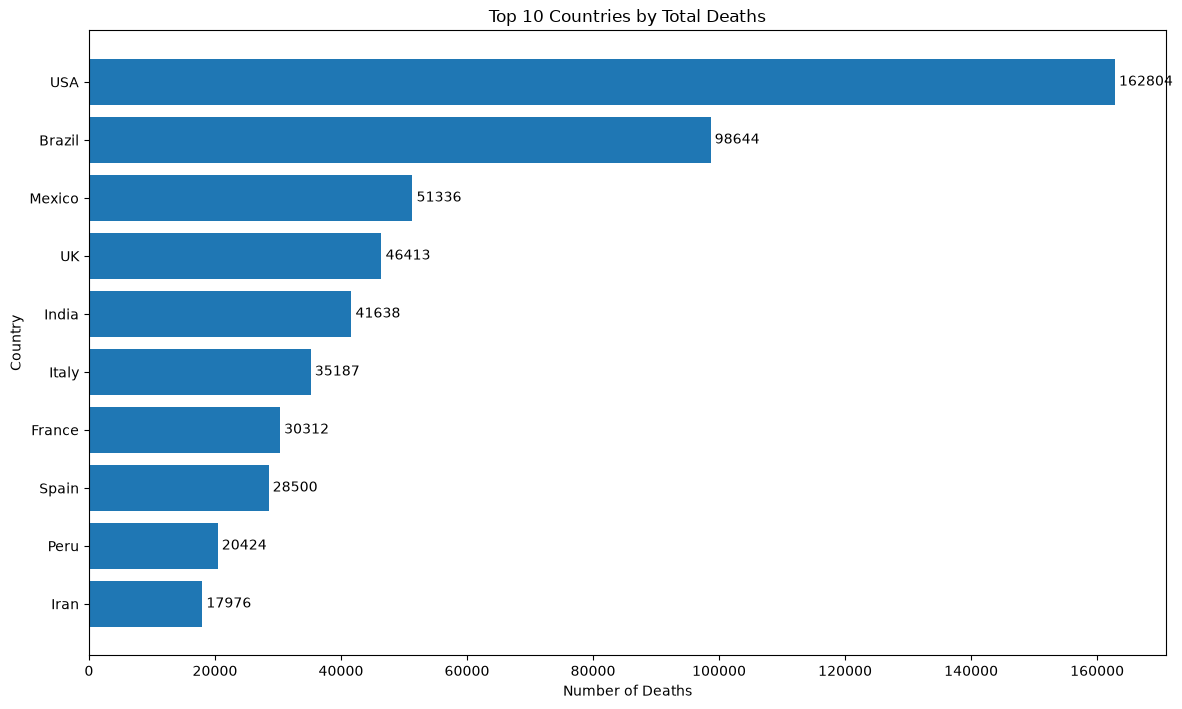

In [89]:
# Top 10 countries with the highest deaths.
world_sorted_death = world.sort_values(by="TotalDeaths", ascending=False)

top10 = world_sorted_death.set_index("Country/Region").head(10).sort_values("TotalDeaths")

# Create figure and axis
fig, ax = plt.subplots(figsize=(12, 7.2))

# Changing the color scheme of the Bars
# colors = 

# Create Horizontal Bars
bars = ax.barh(top10.index, top10["TotalDeaths"])

# Add labels in the bars
ax.bar_label(bars, padding=3)

# Create labels and titles
ax.set_xlabel("Number of Deaths")
ax.set_ylabel("Country")
ax.set_title("Top 10 Countries by Total Deaths")

plt.tight_layout()
plt.show()